In [2]:
import os, json, warnings, pickle, random
from pathlib import Path
warnings.filterwarnings("ignore")

# ----------------------- USER CONFIG -----------------------------------
CSV_PATH   = r"/mnt/c/Users/Ishara/Documents/MPhil/Dataset/Final dataset/without timing/full sim results.csv"  
TARGET_COL = "isUnderAttack"                    
RANDOM_SEED = 42
N_CLASSES = 4
N_TRIALS = 60
N_SPLITS = 3   # K-folds
REPORT_DIR = Path("reports")
MODEL_DIR  = Path("models")
REPORT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
# -----------------------------------------------------------------------

random.seed(RANDOM_SEED)


In [3]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, classification_report, confusion_matrix, roc_curve, auc, precision_recall_curve, average_precision_score

import tensorflow as tf
from tensorflow.keras import layers, regularizers, callbacks
from tensorflow.keras.optimizers import Adam, Nadam, RMSprop


2025-10-14 18:11:57.102149: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-10-14 18:11:57.295506: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-10-14 18:11:57.365807: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-10-14 18:11:57.392658: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-10-14 18:11:57.542484: I tensorflow/core/platform/cpu_feature_guar

In [4]:
df = pd.read_csv(CSV_PATH)

# Features & target
y = df[TARGET_COL].astype(int).values
X = df.drop(columns=[TARGET_COL]).values

# Train/Test split (fixed)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_SEED, stratify=y
)

# Standardize (fit on train only)
scaler_tt = StandardScaler()
X_train = scaler_tt.fit_transform(X_train)
X_test  = scaler_tt.transform(X_test)

print("Train shape:", X_train.shape, " Test shape:", X_test.shape)
print("Class distribution (train):", np.bincount(y_train))
print("Class distribution (test):",  np.bincount(y_test))


Train shape: (43518, 10)  Test shape: (14507, 10)
Class distribution (train): [19329  9736  9719  4734]
Class distribution (test): [6444 3245 3240 1578]


In [5]:
def build_ann(input_dim, n_classes, params):
    # params keys expected:
    # n_hidden_layers, units_{i}, activation_hidden, use_bn, dropout, l2,
    # optimizer, lr, lr_schedule

    reg = regularizers.l2(params["l2"]) if params["l2"] > 0 else None
    inp = layers.Input(shape=(input_dim,))
    x = inp

    for i in range(params["n_hidden_layers"]):
        units_i = params[f"units_{i}"]
        x = layers.Dense(units_i, activation=params["activation_hidden"], kernel_regularizer=reg)(x)
        if params["use_bn"]:
            x = layers.BatchNormalization()(x)
        if params["dropout"] > 0:
            x = layers.Dropout(params["dropout"])(x)

    out = layers.Dense(n_classes, activation="softmax")(x)
    model = tf.keras.Model(inp, out)

    # LR schedule (simple cosine or constant)
    lr = params["lr"]
    if params["lr_schedule"] == "cosine":
        lr_sched = tf.keras.optimizers.schedules.CosineDecayRestarts(
            initial_learning_rate=lr, first_decay_steps=1000
        )
        lr_or_sched = lr_sched
    else:
        lr_or_sched = lr

    if params["optimizer"] == "adam":
        opt = Adam(learning_rate=lr_or_sched)
    elif params["optimizer"] == "nadam":
        opt = Nadam(learning_rate=lr_or_sched)
    else:
        opt = RMSprop(learning_rate=lr_or_sched)

    model.compile(
        optimizer=opt,
        loss="sparse_categorical_crossentropy",
        metrics=["sparse_categorical_accuracy"] 
    )
    return model


In [6]:
class ValF1Macro(callbacks.Callback):
    """
    Computes validation F1-macro at the end of each epoch and writes
    it into logs as 'val_f1_macro' so Keras + Optuna can monitor it.
    """
    def __init__(self, x_val, y_val, batch_size=2048):
        super().__init__()
        self.x_val = x_val
        self.y_val = y_val
        self.batch_size = batch_size
        self.history_vals = []

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        y_prob = self.model.predict(self.x_val, batch_size=self.batch_size, verbose=0)
        y_pred = np.argmax(y_prob, axis=1)
        val_f1 = f1_score(self.y_val, y_pred, average="macro")
        logs["val_f1_macro"] = float(val_f1)
        self.history_vals.append(float(val_f1))
        # Make it visible in notebook output
        print(f" - val_f1_macro: {val_f1:.5f}", end="")


In [7]:
import optuna

SEARCH_SPACE = {
    "n_hidden_layers": "int[2, 6]",
    "units_i (each layer)": "categorical{64, 128, 256, 512, 1024}",
    "activation_hidden": "categorical{'relu','elu','gelu','selu'}",
    "use_bn": "categorical{True, False}",
    "dropout": "float[0.0, 0.5]",
    "l2": "log_float[1e-6, 5e-3]",
    "optimizer": "categorical{'adam','nadam','rmsprop'}",
    "lr": "log_float[5e-5, 5e-3]",
    "lr_schedule": "categorical{'constant','cosine'}",
    "batch_size": "categorical{256, 512, 1024, 2048}",
    "epochs": "int[30, 150]"
}
print("\n=== Hyperparameter Pool (Search Space) ===")
for k, v in SEARCH_SPACE.items():
    print(f"- {k}: {v}")



=== Hyperparameter Pool (Search Space) ===
- n_hidden_layers: int[2, 6]
- units_i (each layer): categorical{64, 128, 256, 512, 1024}
- activation_hidden: categorical{'relu','elu','gelu','selu'}
- use_bn: categorical{True, False}
- dropout: float[0.0, 0.5]
- l2: log_float[1e-6, 5e-3]
- optimizer: categorical{'adam','nadam','rmsprop'}
- lr: log_float[5e-5, 5e-3]
- lr_schedule: categorical{'constant','cosine'}
- batch_size: categorical{256, 512, 1024, 2048}
- epochs: int[30, 150]


In [8]:
%pip install nomkl

Note: you may need to restart the kernel to use updated packages.


In [9]:
def objective(trial: optuna.Trial):
    # Sample params
    params = {
        "n_hidden_layers": trial.suggest_int("n_hidden_layers", 2, 6),
        "activation_hidden": trial.suggest_categorical("activation_hidden", ["relu","elu","gelu","selu"]),
        "use_bn": trial.suggest_categorical("use_bn", [True, False]),
        "dropout": trial.suggest_float("dropout", 0.0, 0.5),
        "l2": trial.suggest_float("l2", 1e-6, 5e-3, log=True),
        "optimizer": trial.suggest_categorical("optimizer", ["adam","nadam","rmsprop"]),
        "lr": trial.suggest_float("lr", 5e-5, 5e-3, log=True),
        "lr_schedule": trial.suggest_categorical("lr_schedule", ["constant","cosine"]),
        "batch_size": trial.suggest_categorical("batch_size", [256, 512, 1024, 2048]),
        "epochs": trial.suggest_int("epochs", 30, 150)
    }
    for i in range(params["n_hidden_layers"]):
        params[f"units_{i}"] = trial.suggest_categorical(f"units_{i}", [64, 128, 256, 512, 1024])

    skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_SEED)
    fold_best_f1 = []

    for fold_idx, (tr_idx, va_idx) in enumerate(skf.split(X_train, y_train), start=1):
        X_tr, X_va = X_train[tr_idx], X_train[va_idx]
        y_tr, y_va = y_train[tr_idx], y_train[va_idx]

        model = build_ann(X_train.shape[1], N_CLASSES, params)

        # Per-fold callbacks
        f1_cb = ValF1Macro(X_va, y_va, batch_size=params["batch_size"])
        early = callbacks.EarlyStopping(
            monitor="val_f1_macro", mode="max", patience=10, restore_best_weights=True
        )

        # Epoch-level pruning (per fold)
        try:
            prune_cb = optuna.integration.TFKerasPruningCallback(trial, "val_f1_macro")
        except Exception:
            class OptunaPruningCallback(tf.keras.callbacks.Callback):
                def __init__(self, trial, monitor="val_f1_macro"):
                    super().__init__()
                    self.trial = trial
                    self.monitor = monitor
                def on_epoch_end(self, epoch, logs=None):
                    val = (logs or {}).get(self.monitor)
                    if val is None: return
                    self.trial.report(float(val), step=epoch)
                    if self.trial.should_prune():
                        raise optuna.TrialPruned(f"Pruned at epoch {epoch} (val_f1_macro={val:.5f})")
            prune_cb = OptunaPruningCallback(trial, monitor="val_f1_macro")

        model.fit(
            X_tr, y_tr,
            validation_data=(X_va, y_va),
            epochs=params["epochs"],
            batch_size=params["batch_size"],
            verbose=0,
            callbacks=[f1_cb, early, prune_cb]
        )

        best_fold_f1 = float(max(f1_cb.history_vals)) if f1_cb.history_vals else 0.0
        fold_best_f1.append(best_fold_f1)

        # Report mean-so-far to allow fold-level pruning
        mean_so_far = float(np.mean(fold_best_f1))
        trial.report(mean_so_far, step=fold_idx)
        if trial.should_prune():
            raise optuna.TrialPruned(f"Pruned after fold {fold_idx} with mean val_f1_macro={mean_so_far:.5f}")

    return float(np.mean(fold_best_f1))

sampler = optuna.samplers.TPESampler(seed=RANDOM_SEED, n_startup_trials=20)
pruner  = optuna.pruners.HyperbandPruner(min_resource=15, max_resource=150, reduction_factor=3)
study = optuna.create_study(direction="maximize", sampler=sampler, pruner=pruner, study_name="ANN_Tabular_10Fold_TPE")

print("\n[Optuna] Optimizing with 10-fold CV on F1-macro...")
study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)

best_params = study.best_params
best_value  = study.best_value
print("\n=== Best Mean CV F1-macro (10-fold) === {:.4f}".format(best_value))
print("=== Best Hyperparameters ===")
print(json.dumps(best_params, indent=2))


[I 2025-10-14 18:12:00,679] A new study created in memory with name: ANN_Tabular_10Fold_TPE



[Optuna] Optimizing with 10-fold CV on F1-macro...


  0%|                                                                                        | 0/60 [00:00<?, ?it/s]WARNING: All log messages before absl::InitializeLog() is called are written to STDERR
I0000 00:00:1760445721.212322     603 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1760445721.361697     603 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1760445721.361785     603 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000 00:00:1760445721.366823     603 cuda_executor.cc:1001] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
I0000

 - val_f1_macro: 0.35008 - val_f1_macro: 0.43661 - val_f1_macro: 0.47047 - val_f1_macro: 0.74459 - val_f1_macro: 0.67721 - val_f1_macro: 0.62773 - val_f1_macro: 0.56883 - val_f1_macro: 0.79826 - val_f1_macro: 0.62648 - val_f1_macro: 0.72135 - val_f1_macro: 0.77919 - val_f1_macro: 0.81962 - val_f1_macro: 0.92724 - val_f1_macro: 0.77816 - val_f1_macro: 0.91077 - val_f1_macro: 0.78362 - val_f1_macro: 0.93276 - val_f1_macro: 0.95829 - val_f1_macro: 0.85874 - val_f1_macro: 0.94946 - val_f1_macro: 0.95226 - val_f1_macro: 0.95634 - val_f1_macro: 0.95924 - val_f1_macro: 0.94103 - val_f1_macro: 0.94217 - val_f1_macro: 0.94913 - val_f1_macro: 0.90430 - val_f1_macro: 0.94306 - val_f1_macro: 0.93558 - val_f1_macro: 0.92727 - val_f1_macro: 0.94125 - val_f1_macro: 0.94263 - val_f1_macro: 0.96692 - val_f1_macro: 0.96145 - val_f1_macro: 0.95579 - val_f1_macro: 0.96906 - val_f1_macro: 0.91530 - val_f1_macro: 0.95957 - val_f1_macro: 0.95477 - val_f1_macro: 0.95872 - val_f1_macro: 0.94953 - val_f1_macro:

Best trial: 0. Best value: 0.960472:   2%|▋                                          | 1/60 [00:38<37:50, 38.49s/it]

...

 - val_f1_macro: 0.94462[I 2025-10-14 18:48:20,404] Trial 58 pruned. Trial was pruned at epoch 15.


2025-10-14 18:48:24.449374: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:393] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_55', 4 bytes spill stores, 4 bytes spill loads

2025-10-14 18:48:24.518305: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:393] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_55', 132 bytes spill stores, 132 bytes spill loads

2025-10-14 18:48:24.789484: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:393] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_55', 1444 bytes spill stores, 1784 bytes spill loads



 - val_f1_macro: 0.75640 - val_f1_macro: 0.78151 - val_f1_macro: 0.85521 - val_f1_macro: 0.87914 - val_f1_macro: 0.89939 - val_f1_macro: 0.90571 - val_f1_macro: 0.91272 - val_f1_macro: 0.92040 - val_f1_macro: 0.92616 - val_f1_macro: 0.92736 - val_f1_macro: 0.92768 - val_f1_macro: 0.93072 - val_f1_macro: 0.93237 - val_f1_macro: 0.93361 - val_f1_macro: 0.93367

Best trial: 52. Best value: 0.978723: 100%|█████████████████████████████████████████| 60/60 [36:29<00:00, 36.48s/it]

 - val_f1_macro: 0.93350[I 2025-10-14 18:48:29,730] Trial 59 pruned. Trial was pruned at epoch 15.

=== Best Mean CV F1-macro (10-fold) === 0.9787
=== Best Hyperparameters ===
{
  "n_hidden_layers": 2,
  "activation_hidden": "relu",
  "use_bn": true,
  "dropout": 0.07816451844305984,
  "l2": 0.0018067201114756084,
  "optimizer": "nadam",
  "lr": 0.0024901124769445967,
  "lr_schedule": "cosine",
  "batch_size": 512,
  "epochs": 130,
  "units_0": 1024,
  "units_1": 256
}


In [10]:
# Ensure per-layer units exist
for i in range(best_params["n_hidden_layers"]):
    if f"units_{i}" not in best_params:
        best_params[f"units_{i}"] = 256

final_model = build_ann(X_train.shape[1], N_CLASSES, best_params)

# Use a small internal validation split only to drive EarlyStopping
X_tr2, X_val2, y_tr2, y_val2 = train_test_split(
    X_train, y_train, test_size=0.15, random_state=RANDOM_SEED, stratify=y_train
)

f1_cb2 = ValF1Macro(X_val2, y_val2, batch_size=best_params["batch_size"])
early2 = callbacks.EarlyStopping(
    monitor="val_f1_macro", mode="max", patience=12, restore_best_weights=True
)

hist_final = final_model.fit(
    X_tr2, y_tr2,
    validation_data=(X_val2, y_val2),
    epochs=best_params["epochs"],
    batch_size=best_params["batch_size"],
    verbose=1,
    callbacks=[f1_cb2, early2]
)


Epoch 1/130
73/73 ━━━━━━━━━━━━━━━━━━━━ 5s 41ms/step - loss: 0.9879 - sparse_categorical_accuracy: 0.8805 - val_loss: 1.5670 - val_sparse_categorical_accuracy: 0.4340 - val_f1_macro: 0.4239
Epoch 2/130
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4912 - sparse_categorical_accuracy: 0.9452 - val_loss: 1.3660 - val_sparse_categorical_accuracy: 0.4393 - val_f1_macro: 0.4460
Epoch 3/130
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3291 - sparse_categorical_accuracy: 0.9496 - val_loss: 1.1442 - val_sparse_categorical_accuracy: 0.4118 - val_f1_macro: 0.4049
Epoch 4/130
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2329 - sparse_categorical_accuracy: 0.9573 - val_loss: 1.0906 - val_sparse_categorical_accuracy: 0.4354 - val_f1_macro: 0.4265
Epoch 5/130
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1923 - sparse_categorical_accuracy: 0.9582 - val_loss: 0.8815 - val_sparse_categorical_accuracy: 0.5619 - val_f1_macro: 0.5046
Epoch 6/130
73/73 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 

In [11]:
y_prob_test = final_model.predict(X_test, batch_size=2048, verbose=0)
y_pred_test = np.argmax(y_prob_test, axis=1)

test_acc = np.mean(y_pred_test == y_test)
test_f1_macro = f1_score(y_test, y_pred_test, average="macro")
test_f1_weighted = f1_score(y_test, y_pred_test, average="weighted")

print("\n=== Test Set Metrics ===")
print(f"Accuracy:     {test_acc:.4f}")
print(f"F1-macro:     {test_f1_macro:.4f}")
print(f"F1-weighted:  {test_f1_weighted:.4f}")

print("\n=== Classification Report (Test) ===")
print(classification_report(y_test, y_pred_test, digits=4))



=== Test Set Metrics ===
Accuracy:     0.9753
F1-macro:     0.9768
F1-weighted:  0.9752

=== Classification Report (Test) ===
              precision    recall  f1-score   support

           0     0.9744    0.9867    0.9805      6444
           1     0.9811    0.9587    0.9698      3245
           2     0.9601    0.9583    0.9592      3240
           3     0.9981    0.9975    0.9978      1578

    accuracy                         0.9753     14507
   macro avg     0.9784    0.9753    0.9768     14507
weighted avg     0.9753    0.9753    0.9752     14507



In [12]:
cm = confusion_matrix(y_test, y_pred_test)
print("Confusion Matrix:\n", cm)


Confusion Matrix:
 [[6358   24   59    3]
 [  64 3111   70    0]
 [  99   36 3105    0]
 [   4    0    0 1574]]


In [13]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

def _light_blue_cmap():
    
    colors = [
        (1.00, 1.00, 1.00),  # white
        (0.92, 0.96, 1.00),
        (0.85, 0.93, 1.00),
        (0.75, 0.88, 1.00),
        (0.65, 0.83, 1.00),
        (0.55, 0.78, 0.98),
    ]
    return LinearSegmentedColormap.from_list("light_blues", colors, N=256)

def plot_confusion_matrix(
    cm: np.ndarray,
    classes,
    normalize: bool = False,
    title: str = "Confusion Matrix",
    figsize=(6, 5),
):
    """
    Plot a confusion matrix using a **light pastel** colormap (no seaborn).
    - normalize=True shows per-row (recall) percentages.
    """
    if normalize:
        with np.errstate(all="ignore"):
            cm_display = cm.astype("float") / cm.sum(axis=1, keepdims=True)
        cm_display = np.nan_to_num(cm_display)
        fmt = ".2f"
        vmin, vmax = 0.0, 1.0
    else:
        cm_display = cm
        fmt = "d"
        vmin, vmax = 0, cm_display.max() if cm_display.size else 1

    cmap = _light_blue_cmap()

    fig, ax = plt.subplots(figsize=figsize, dpi=140)
    im = ax.imshow(cm_display, interpolation="nearest", cmap=cmap, vmin=vmin, vmax=vmax)

    # Axes labels/ticks
    ax.set_title(title, fontsize=12, pad=10)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_xticks(np.arange(len(classes)))
    ax.set_yticks(np.arange(len(classes)))
    ax.set_xticklabels(classes, rotation=45, ha="right")
    ax.set_yticklabels(classes)

    # Colorbar (compact)
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.ax.tick_params(labelsize=8)

    # Gridlines for readability
    ax.set_xticks(np.arange(-0.5, len(classes), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, len(classes), 1), minor=True)
    ax.grid(which="minor", color=(0, 0, 0, 0.06), linestyle="-", linewidth=0.8)
    ax.tick_params(which="minor", bottom=False, left=False)

    # Annotate each cell
    # Use dark text everywhere (pastel background ensures contrast)
    for i in range(cm_display.shape[0]):
        for j in range(cm_display.shape[1]):
            val = cm_display[i, j]
            ax.text(
                j, i, format(val, fmt),
                ha="center", va="center",
                fontsize=10, color="black"
            )

    plt.tight_layout()
    plt.show()


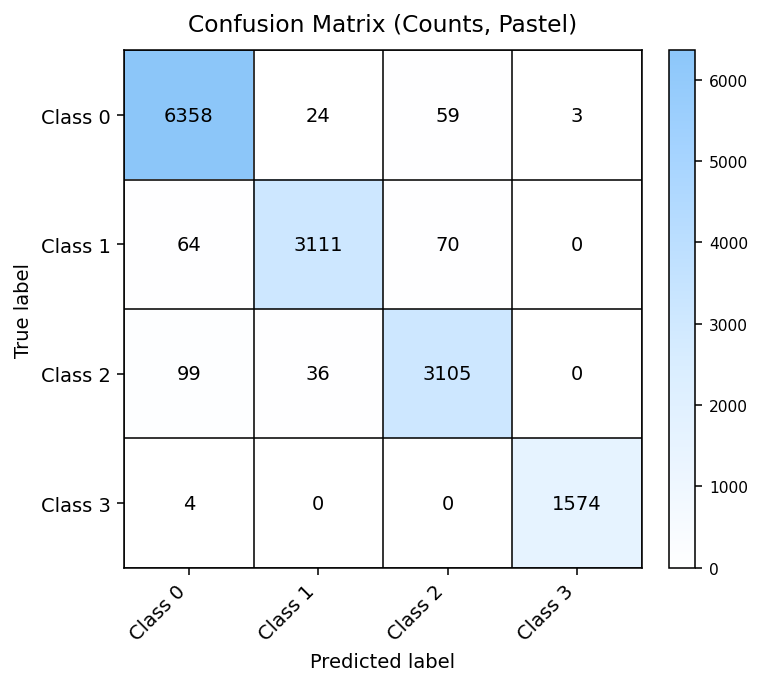

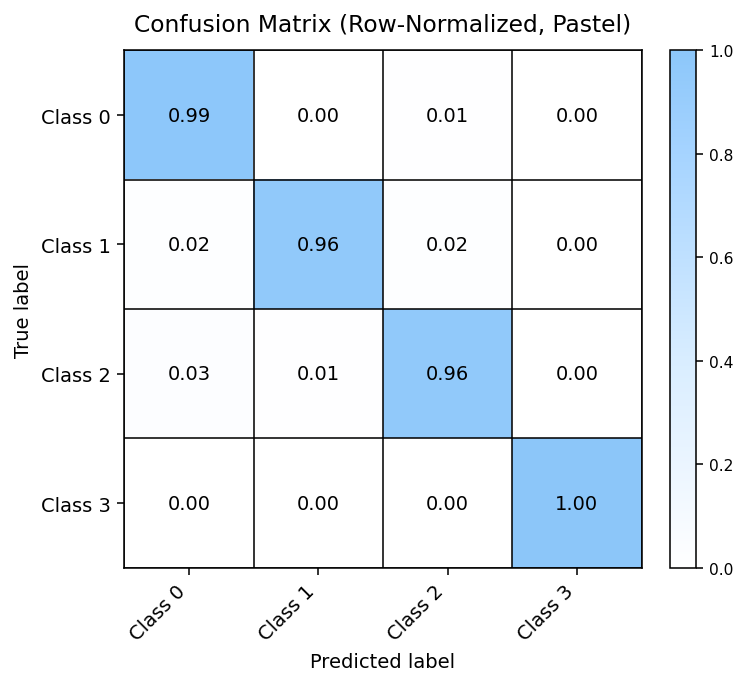

In [14]:
from sklearn.metrics import confusion_matrix



cm = confusion_matrix(y_test, y_pred_test)

class_labels = [f"Class {i}" for i in range(np.unique(y_test).size)]  # or your actual names

plot_confusion_matrix(
    cm, classes=class_labels,
    normalize=False,
    title="Confusion Matrix (Counts, Pastel)"
)

plot_confusion_matrix(
    cm, classes=class_labels,
    normalize=True,
    title="Confusion Matrix (Row-Normalized, Pastel)"
)


In [15]:
Y_test_ovr = np.eye(N_CLASSES)[y_test]

# ROC
fpr, tpr, roc_auc = {}, {}, {}
for i in range(N_CLASSES):
    fpr[i], tpr[i], _ = roc_curve(Y_test_ovr[:, i], y_prob_test[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])
fpr["micro"], tpr["micro"], _ = roc_curve(Y_test_ovr.ravel(), y_prob_test.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])
print("ROC AUC (per class):", {i: f"{roc_auc[i]:.4f}" for i in range(N_CLASSES)})
print("ROC AUC (micro):", f"{roc_auc['micro']:.4f}")

# PR
prec, rec, ap = {}, {}, {}
for i in range(N_CLASSES):
    prec[i], rec[i], _ = precision_recall_curve(Y_test_ovr[:, i], y_prob_test[:, i])
    ap[i] = average_precision_score(Y_test_ovr[:, i], y_prob_test[:, i])
prec["micro"], rec["micro"], _ = precision_recall_curve(Y_test_ovr.ravel(), y_prob_test.ravel())
ap["micro"] = average_precision_score(Y_test_ovr, y_prob_test, average="micro")
print("PR AUC / AP (per class):", {i: f"{ap[i]:.4f}" for i in range(N_CLASSES)})
print("PR AUC / AP (micro):", f"{ap['micro']:.4f}")


ROC AUC (per class): {0: '0.9990', 1: '0.9993', 2: '0.9980', 3: '1.0000'}
ROC AUC (micro): 0.9994
PR AUC / AP (per class): {0: '0.9988', 1: '0.9977', 2: '0.9940', 3: '1.0000'}
PR AUC / AP (micro): 0.9981


In [16]:
def tpr_at_fixed_fpr(fpr_arr, tpr_arr, target_fpr=0.01):
    if target_fpr <= fpr_arr[0]:
        return float(tpr_arr[0])
    if target_fpr >= fpr_arr[-1]:
        return float(tpr_arr[-1])
    return float(np.interp(target_fpr, fpr_arr, tpr_arr))

targets = [0.01, 0.05]
print("\n===== TPR at fixed FPRs =====")
for tg in targets:
    line = [f"FPR={tg*100:.0f}%"]
    for i in range(N_CLASSES):
        tpr_val = tpr_at_fixed_fpr(fpr[i], tpr[i], tg)
        line.append(f"class {i} TPR={tpr_val:.4f}")
    tpr_micro = tpr_at_fixed_fpr(fpr["micro"], tpr["micro"], tg)
    line.append(f"micro TPR={tpr_micro:.4f}")
    print("  " + "  |  ".join(line))



===== TPR at fixed FPRs =====
  FPR=1%  |  class 0 TPR=0.9635  |  class 1 TPR=0.9744  |  class 2 TPR=0.9540  |  class 3 TPR=1.0000  |  micro TPR=0.9795
  FPR=5%  |  class 0 TPR=0.9998  |  class 1 TPR=0.9991  |  class 2 TPR=0.9849  |  class 3 TPR=1.0000  |  micro TPR=0.9997


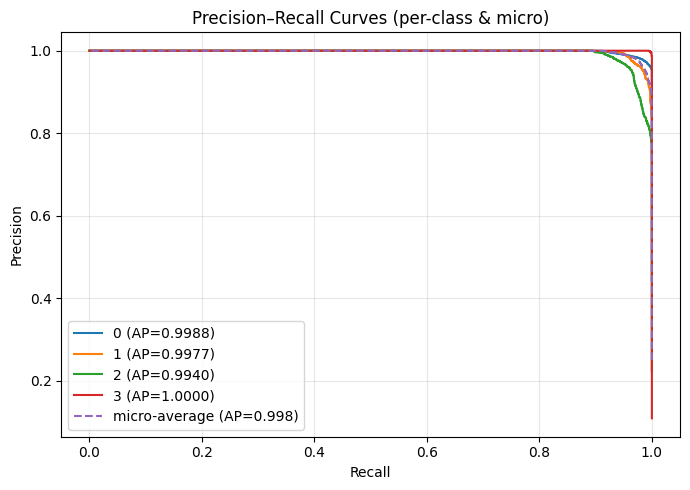

Average Precision (per class): {0: '0.9988', 1: '0.9977', 2: '0.9940', 3: '1.0000'}
Micro-average AP: 0.9981


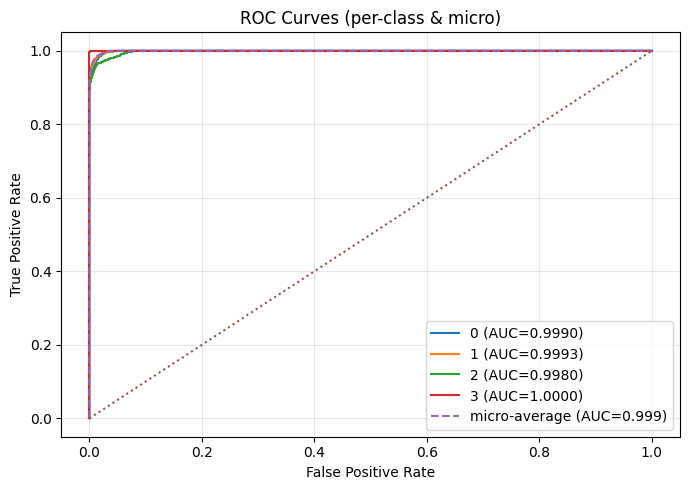

ROC AUC (per class): {0: '0.9990', 1: '0.9993', 2: '0.9980', 3: '1.0000'}
Micro-average AUC: 0.9994


In [17]:
# === PR & ROC curves (uses: final_model, X_test, y_test, N_CLASSES) ===
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    precision_recall_curve, average_precision_score,
    roc_curve, roc_auc_score, auc
)

# 0) Sanity checks
_required = ["final_model", "X_test", "y_test", "N_CLASSES"]
_missing = [v for v in _required if v not in globals()]
if _missing:
    raise RuntimeError(f"Missing required variables in this notebook: {_missing}")

# 1) Get predicted probabilities
if "y_prob_test" not in globals():
    # Matches your evaluation cell (batch_size=2048, verbose=0)
    y_prob_test = final_model.predict(X_test, batch_size=2048, verbose=0)

y_prob_test = np.asarray(y_prob_test)
if y_prob_test.ndim == 1:
    y_prob_test = y_prob_test.reshape(-1, 1)

# 2) Build one-vs-rest labels for metrics/plots
y_true = np.asarray(y_test)
if y_true.ndim == 1:
    Y_test_ovr = np.eye(N_CLASSES)[y_true]
elif y_true.ndim == 2 and y_true.shape[1] == N_CLASSES:
    Y_test_ovr = y_true
else:
    raise ValueError("y_test has an unexpected shape; expected (n,) label vector or one-hot (n, N_CLASSES).")

# Optional class labels for legends
CLASS_NAMES = [str(i) for i in range(N_CLASSES)]

# ---------------------- Precision–Recall ----------------------
aps = {}
plt.figure(figsize=(7, 5))

for i in range(N_CLASSES):
    p, r, _ = precision_recall_curve(Y_test_ovr[:, i], y_prob_test[:, i])
    ap = average_precision_score(Y_test_ovr[:, i], y_prob_test[:, i])
    aps[i] = ap
    plt.plot(r, p, label=f"{CLASS_NAMES[i]} (AP={ap:.4f})")

# Micro-average
p_micro, r_micro, _ = precision_recall_curve(Y_test_ovr.ravel(), y_prob_test.ravel())
ap_micro = average_precision_score(Y_test_ovr, y_prob_test, average="micro")
plt.plot(r_micro, p_micro, linestyle="--", label=f"micro-average (AP={ap_micro:.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curves (per-class & micro)")
plt.legend(loc="best")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Average Precision (per class):", {i: f"{aps[i]:.4f}" for i in range(N_CLASSES)})
print(f"Micro-average AP: {ap_micro:.4f}")

# --------------------------- ROC ------------------------------
rocs = {}
plt.figure(figsize=(7, 5))

for i in range(N_CLASSES):
    fpr, tpr, _ = roc_curve(Y_test_ovr[:, i], y_prob_test[:, i])
    auc_i = auc(fpr, tpr)
    rocs[i] = auc_i
    plt.plot(fpr, tpr, label=f"{CLASS_NAMES[i]} (AUC={auc_i:.4f})")

# Micro-average ROC
fpr_micro, tpr_micro, _ = roc_curve(Y_test_ovr.ravel(), y_prob_test.ravel())
auc_micro = auc(fpr_micro, tpr_micro)
plt.plot(fpr_micro, tpr_micro, linestyle="--", label=f"micro-average (AUC={auc_micro:.3f})")

# Chance line
plt.plot([0, 1], [0, 1], linestyle=":")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves (per-class & micro)")
plt.legend(loc="best")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("ROC AUC (per class):", {i: f"{rocs[i]:.4f}" for i in range(N_CLASSES)})
print(f"Micro-average AUC: {auc_micro:.4f}")


In [18]:
(final_model).save(MODEL_DIR / "ann_best_f1macro.h5")
with open(MODEL_DIR / "scaler_f1macro.pkl", "wb") as f:
    pickle.dump(scaler_tt, f)
with open(MODEL_DIR / "best_params_f1macro.json", "w") as f:
    json.dump(best_params, f, indent=2)

print(f"\n[Saved] { (MODEL_DIR / 'ann_best.h5').resolve() }")
print(f"[Saved] { (MODEL_DIR / 'scaler.pkl').resolve() }")
print(f"[Saved] { (MODEL_DIR / 'best_params.json').resolve() }")



[Saved] /home/ubuntu1/projects/MPhilCodes/models/ann_best.h5
[Saved] /home/ubuntu1/projects/MPhilCodes/models/scaler.pkl
[Saved] /home/ubuntu1/projects/MPhilCodes/models/best_params.json
